# LacZ gene expression prediction

This notebook iteratively builds a neural network model to predict the gene expression of the lacZ gene. 



# Imports

In [356]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn, optim
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_regression
from torch.optim.lr_scheduler import StepLR
from torchmetrics.regression import R2Score


The next cell is there to ensure the reproducibility of the results in the notebook.

In [357]:
torch.manual_seed(42)
torch.use_deterministic_algorithms(True)

# Importing the data

In [358]:
# importing the data
ecoli_data = pd.read_csv("Ecoli70_sample_data.csv")
ecoli_data.head()

,aceB,asnA,atpD,atpG,b1191,b1583,b1963,cchB,cspA,cspG,...,ycgX,yecO,yedE,yfaD,yfiA,ygbD,ygcE,yhdM,yheI,yjbO
0,-0.445526,1.978713,-2.549478,-0.252823,1.5544,1.652422,2.355826,2.183165,1.140734,2.0356,...,3.788800,1.404237,-1.363925,2.262000,-1.429529,2.349890,1.206950,0.295347,1.792500,-0.041388
1,-2.259937,2.191567,-1.378039,-1.773287,0.5815,2.201096,0.322306,1.261700,1.140734,2.6415,...,3.348214,2.556826,-1.104275,1.687592,0.242876,2.308967,3.816295,0.112664,2.224780,3.867987
2,-1.879900,0.124127,-2.137881,-0.991434,1.6359,1.304056,0.796235,2.501742,1.757104,2.7852,...,-0.098174,1.722376,-2.383128,0.438348,-1.192944,1.114931,1.325217,0.018071,2.334192,1.875800
3,-1.059960,1.698421,-2.934233,-2.359600,0.0000,1.134377,1.527573,2.674006,0.749870,2.7007,...,2.075466,2.811632,0.000000,0.482017,0.242876,1.517561,3.334756,1.173264,1.707712,0.993384
4,-2.045524,2.096300,-2.938159,-2.516266,1.8096,2.453704,0.804432,2.422300,0.774266,2.4636,...,-0.145078,2.403100,-2.406891,0.004852,-1.031414,2.528200,1.206950,0.819972,0.701783,-0.041388


The datset consists of 1000 rows and 46 columns. Each row represents a distinct experimental condition or time point, and each column represents a gene. There are not a lot of rows in the datset compared to datsets that are usually used to train neural networks. This means the neural network that will be built will most likely overfit.

In [359]:
# defining the target variable
target = "lacZ"

## Exploratory data analysis

We checked for missing values in the dataset and looked at the distribution of all variables in the dataset to look for unusual values that could badly influence the performance of the neural network model.

In [360]:
# checking for missing values
ecoli_data.isnull().sum().sum()

np.int64(0)

In [361]:
len(pd.unique(ecoli_data["atpD"]))

81

In [362]:
len(pd.unique(ecoli_data["lacZ"]))

81

In [363]:
ecoli_data.describe()


,aceB,asnA,atpD,atpG,b1191,b1583,b1963,cchB,cspA,cspG,...,ycgX,yecO,yedE,yfaD,yfiA,ygbD,ygcE,yhdM,yheI,yjbO
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,-1.437118,1.974696,-1.899778,-1.742790,1.298103,1.797668e+00,2.142720,1.969710,0.134795,2.028454,...,1.123202,1.860731,-1.480917,1.143442,-1.026867,2.292175,2.089336,1.273111,1.079825,1.405481
std,0.904118,0.834928,1.071475,0.875758,0.741553,7.955169e-01,1.070237,0.959868,1.131650,0.961316,...,1.162652,0.893973,0.782201,0.807146,1.100066,1.061612,1.035000,1.073946,0.899111,1.180817
min,-2.877693,-0.004744,-4.337926,-3.511706,0.000000,-1.776357e-15,-0.014007,0.000000,-2.246616,0.000000,...,-0.510249,-0.553995,-2.915432,-0.361854,-3.150271,0.000000,0.000000,-0.590025,-0.626480,-0.249552
25%,-2.101507,1.499733,-2.781732,-2.455200,0.581500,1.304056e+00,1.320000,1.265793,-0.943947,2.035600,...,0.121227,1.335703,-2.018380,0.482017,-1.892126,1.461612,1.325217,0.295347,0.384394,0.592109
50%,-1.838663,1.978713,-1.893986,-1.652397,1.390600,1.837917e+00,2.002886,1.952922,0.163353,2.463600,...,1.124900,2.099639,-1.581697,0.981752,-1.169832,2.334013,2.027387,1.413064,0.865170,1.091638
75%,-0.603225,2.657914,-1.226476,-1.135961,1.635900,2.295300e+00,2.953200,2.573873,0.955491,2.700700,...,1.700365,2.503997,-1.058690,1.828007,-0.060348,2.937331,2.796705,2.003089,1.914546,1.912995
max,0.795650,3.445563,0.597292,0.000000,2.592300,3.571420e+00,4.457851,4.688403,1.917031,2.892000,...,4.480592,3.184721,0.477422,2.769283,1.595984,5.068692,4.764713,3.885578,2.863512,4.034854


The data has already been normalised, so it is hard to tell which variables originally had a low standard deviation (features with a low standard deviation could have been removed from the list of predictors in the final model, as they are not informative) and results will be hard to interpret. All gene expressions have discrete values and most of them take 81 different values. There are no abnormaly high or low values in the dataset. 

Correlations between all variables in the dataset were then computed.

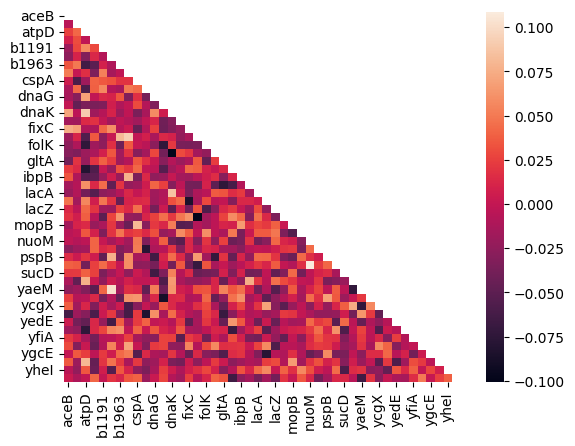

In [364]:
# Correlation matrix
corr = ecoli_data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
sns.heatmap(corr, mask=mask)
plt.show()


The correlation matrix does not reveal high correlations between any variables : the highest correlation coefficient are 0.1 in absolute value. This highlights that relationships between variables are not linear. Our model will have to learn non-linear relationships.

### Preprocessing

The data was split between a training and a testing dataset. 20% of the entire dataset is used for testing. A standard scaler was fitted to the training data and used to scale both the training and testing data. The scaler was only fitted on the training data to ensure no data leakage. A random seed was used to make the split to ensure reproducibility of the results. The same split was used in the entire notebook. Data was then transformed into tensors to be able to use them in models. 

In [365]:
# standardise all features and split the data into training and testing dataset
X = ecoli_data.drop(["lacZ"], axis=1)
y = ecoli_data["lacZ"]
y = np.array(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

sd_X = StandardScaler()
X_train_scaled = sd_X.fit_transform(X_train)
X_test_scaled = sd_X.transform(X_test)

In [366]:
# convert the data to pytorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

## Iteration 1 : baseline model

## Motivation and hypothesis

A simple baseline model was built first to establish a reference point and identify the dominant failure modes before introducing more sophisticated techniques. Using all 45 features with no explicit feature selection or L1 regularisation was expected to reveal whether overfitting would be an issue with the full input space. 

## Architecture and training procedure

A simple model with two hidden layers: one with 64 neurons and a second one with 32 neurons. ReLU activation was used on both hidden layers. Additionally, dropout was implemented to reduce overfitting. The weights were initialised using the He initialisation method and the biased were initialised at 0.01. The model was trained for 100 epochs and mean squared error was the loss function. A learning rate scheduler was used, starting with a learning rate of 0.01 and using exponential decay (exponentially decreasing the learning rate at each epoch). The data was processed in batches of size 64.


In [367]:
# defining the model
class GeneNN_baseline(nn.Module):
    def __init__(self, input_dim, init_method="xavier"):
        super(GeneNN_baseline, self).__init__()

        # Layers with Batch Normalization
        self.fc1 = nn.Linear(input_dim, 64)
        self.bn1 = nn.BatchNorm1d(64)
        self.fc2 = nn.Linear(64, 32)
        self.bn2 = nn.BatchNorm1d(32)
        self.fc3 = nn.Linear(32, 1)

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Initialize weights
        self.init_weights(init_method)

    def init_weights(self, method):
        for layer in [self.fc1, self.fc2, self.fc3]:
            if method == "xavier":
                nn.init.xavier_uniform_(layer.weight)
            elif method == "he":
                nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            elif method == "normal":
                nn.init.normal_(layer.weight, mean=0, std=0.1)
            layer.bias.data.fill_(0.01)

    def forward(self, x):
        x = F.relu(self.bn1(self.fc1(x)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        return self.fc3(x)

In [368]:
# Defining a function that trains the model
def train_model(model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
                num_epochs=100, batch_size=64, lr=0.01, weight_decay=1e-4):

    # Loss and Optimizer
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)  # L2 regularization
    scheduler = StepLR(optimizer, step_size=10, gamma=0.5)  # Learning rate scheduler

    # Training loop
    num_epochs = num_epochs
    batch_size = batch_size
    num_batches = len(X_train_tensor) // batch_size

    train_losses = []
    val_losses = []

    train_r2 = []
    val_r2 = []

    for epoch in range(num_epochs):
        # Training phase
        model.train()
        epoch_loss = 0
        train_r2_metric = R2Score()

        for i in range(num_batches):
            start_idx = i * batch_size
            end_idx = start_idx + batch_size
            X_batch = X_train_tensor[start_idx:end_idx]
            y_batch = y_train_tensor[start_idx:end_idx]

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            train_r2_metric.update(predictions, y_batch)
        
        train_loss = epoch_loss / num_batches
        train_losses.append(train_loss)

        # Validation phase
        model.eval()
        val_r2_metric = R2Score()

        with torch.no_grad():
            val_predictions = model(X_test_tensor)
            val_loss = criterion(val_predictions, y_test_tensor)
            val_r2_metric.update(val_predictions, y_test_tensor)
        
        # Adding the validation loss to the list
        val_losses.append(val_loss.item())

        # Adding r squared scores
        train_r2.append(train_r2_metric.compute().item())
        val_r2.append(val_r2_metric.compute().item())

        scheduler.step()

        # Print progress
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")
        
    # Returning losses and r squared
    return train_losses, val_losses, train_r2, val_r2

In [369]:
input_dim = X_train_tensor.shape[1]
model_baseline = GeneNN_baseline(input_dim, init_method="he")
train_l, val_l, train_r, val_r = train_model(model_baseline,
                                            X_train_tensor, y_train_tensor,
                                            X_test_tensor, y_test_tensor
                                            )

Epoch 10/100, Train Loss: 2.3278, Val Loss: 2.3181
Epoch 20/100, Train Loss: 2.0213, Val Loss: 2.3386
Epoch 30/100, Train Loss: 2.0015, Val Loss: 2.3363
Epoch 40/100, Train Loss: 1.8284, Val Loss: 2.3483
Epoch 50/100, Train Loss: 1.8262, Val Loss: 2.3484
Epoch 60/100, Train Loss: 1.7839, Val Loss: 2.3389
Epoch 70/100, Train Loss: 1.7646, Val Loss: 2.3470
Epoch 80/100, Train Loss: 1.8649, Val Loss: 2.3490
Epoch 90/100, Train Loss: 1.7478, Val Loss: 2.3436
Epoch 100/100, Train Loss: 1.7760, Val Loss: 2.3476


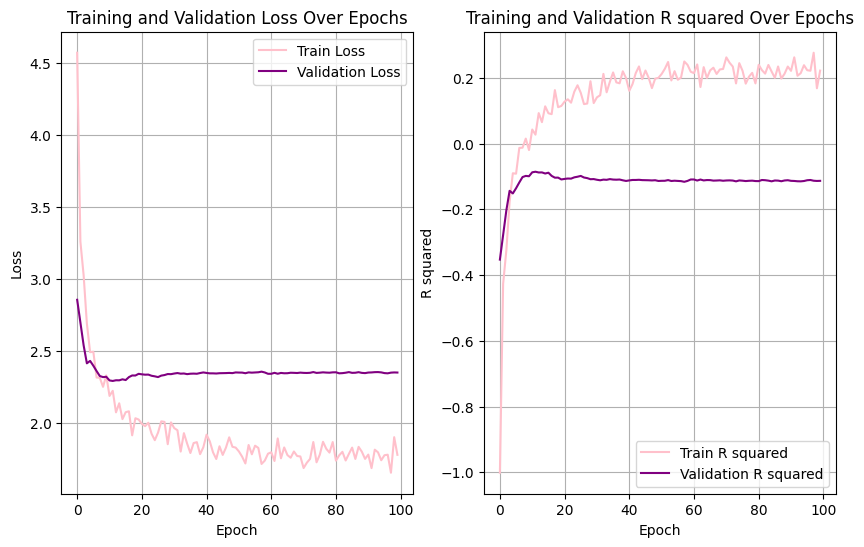

In [370]:
# tracking down the train / validation losses and r squared score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

ax1.plot(train_l, color="pink", label='Train Loss')
ax1.plot(val_l, color="purple", label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss Over Epochs')
ax1.legend()
ax1.grid()

ax2.plot(train_r, color="pink", label='Train R squared')
ax2.plot(val_r, color="purple", label='Validation R squared')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('R squared')
ax2.set_title('Training and Validation R squared Over Epochs')
ax2.legend()
ax2.grid()

plt.show()

## Results analysis

The model overfits a lot. There is a high difference between the training and the testing curves. Moreover, the R squared value on the validation set is lower than 0, meaning that the model is doing worse than guessing the value at random. Training loss decreases steadily from 2.33 to 1.78 across 100 epochs while the validation loss remains flat around 2.32-2.35, confirming that the model is memorising the training data rather than learning generalizable patterns. The persistent negative validation R squared indicates that using all 45 features with no feature selection gives the model opportunity to fit noise into it. 

This is the motivation for what was done in the second iteration : selecting a subset of features to train the model on.

# Iteration 2 : Selecting a subset of features

## Motivation and hypothesis

As a lot of the genes present in the dataset code similar information, some features are bound to contain the same information as others and removing some of the features may help the model learn real relationships and improve scores as aforementioned. The same model as iteration 1 was kept to be able to estimate the effects of the feature selection technique alone. The same training function was used and no other regularisation strategy was implemented. 

## Architecture and training procedure

It is identical to iteration 1 in all aspects except the input dimension, which was reduced from 45 to 30 using the top 30 features by mutual information score, implemented in scikit learn. This uses k-nearest neighbors to estimate each feature's importance, meaning it can capture non-linear relationships, which is crucial in our case, considering the relationships between features are not linear.

In [371]:
# trying to do feature selection
mi_scores = mutual_info_regression(X_train_tensor, y_train_tensor,
                                   random_state=42, n_neighbors=5)
df_info = pd.DataFrame({"column":X_train.columns, "score_mutual_info":mi_scores})
df_info.sort_values(by="score_mutual_info", ascending=False)

c:\Users\Elise\anaconda3\envs\cs987\lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,column,score_mutual_info
9,cspG,0.136559
4,b1191,0.112969
13,eutG,0.112374
27,nuoM,0.081365
7,cchB,0.080223
42,yhdM,0.080123
0,aceB,0.078419
44,yjbO,0.077889
36,yecO,0.069906
23,lacY,0.064964


In [372]:
# we select the top 30 most relevant features to train the model on
selected_indices = np.argsort(mi_scores)[-30:]
X_selected = X_train_tensor[:, selected_indices]
X_test_selected = X_test_tensor[:, selected_indices]

In [373]:
input_dim = X_selected.shape[1]
model_feature_selection = GeneNN_baseline(input_dim, init_method="he")
train_l, val_l, train_r, val_r = train_model(model_feature_selection,
                                            X_selected, y_train_tensor,
                                            X_test_selected, y_test_tensor)

Epoch 10/100, Train Loss: 2.4390, Val Loss: 2.2686
Epoch 20/100, Train Loss: 2.0901, Val Loss: 2.2765
Epoch 30/100, Train Loss: 2.0898, Val Loss: 2.2668
Epoch 40/100, Train Loss: 2.0426, Val Loss: 2.2615
Epoch 50/100, Train Loss: 2.0014, Val Loss: 2.2678
Epoch 60/100, Train Loss: 1.9625, Val Loss: 2.2670
Epoch 70/100, Train Loss: 1.9734, Val Loss: 2.2612
Epoch 80/100, Train Loss: 1.8867, Val Loss: 2.2615
Epoch 90/100, Train Loss: 2.0086, Val Loss: 2.2689
Epoch 100/100, Train Loss: 1.8269, Val Loss: 2.2699


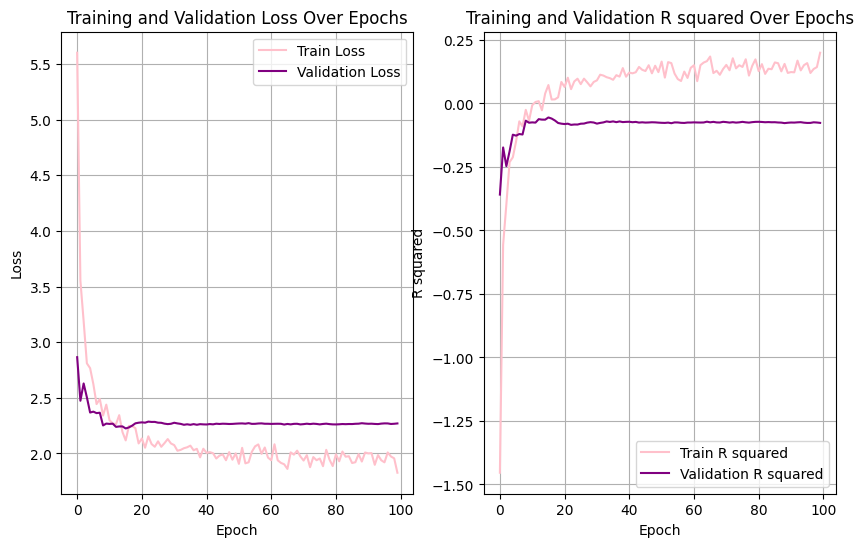

In [374]:
# tracking down the train / validation losses and r squared score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

ax1.plot(train_l, color="pink", label='Train Loss')
ax1.plot(val_l, color="purple", label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss Over Epochs')
ax1.legend()
ax1.grid()

ax2.plot(train_r, color="pink", label='Train R squared')
ax2.plot(val_r, color="purple", label='Validation R squared')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('R squared')
ax2.set_title('Training and Validation R squared Over Epochs')
ax2.legend()
ax2.grid()

plt.show()

## Results analysis

The validation scores in this iteration are slightly better than the previous one. The mean squared error was 2.34 in the previous iteration and the best validation loss is 2.2612 in the current one (achieved at epoch 70). The training loss scores are higher, indicating that there is less overfitting in this iteration.  

However, we can see on the plots that there is still a large gap between the training curve and the validation one, so regularisation strategies (other than simply dropout or batch normalisation) need to be implemented. 

This is therefore what was added in the next iteration.

# Iteration 3 : adding regularization techniques

## Motivation and hypothesis

The main difference in this iteration is the training of the model. The subset of features selected in the previous iteration was kept, as the scores improved slightly but regularisation techniques were added to reduce overfitting. L1 regularisation was added, with the possibility to tune the parameter through lambda_l1. The batch size was also tuned, as increasing the batch size can help the model generalise better, and thus, reduce overfitting.

## Architecture and training

The same architecture as before was used (using two hidden layers), and the model was trained on the same subset of features. The model description was slightly changed to be able to change the dropout rate manually.

The model training function was modified to add L1 regularization to the loss function. The l1 regularisation parameters, batch size, starting point of the learning rate scheduler and dropout rate were manually tuned to obtain optimal results.

The final values of each of these hyperparameters are : 

- lambda_l1 = 0.1
- batch_size = 100
- lr = 0.01
- dropout_rate = 0.35

In [375]:
class GeneNN_1(nn.Module):
    def __init__(self, input_dim, init_method="xavier", dropout_rate=0.3):
        super(GeneNN_1, self).__init__()

        # Layers with Batch Normalization
        self.fc1 = nn.Linear(input_dim, 64)
        self.bn1 = nn.BatchNorm1d(64)
        self.fc2 = nn.Linear(64, 32)
        self.bn2 = nn.BatchNorm1d(32)
        self.fc3 = nn.Linear(32, 1)

        # Dropout
        self.dropout = nn.Dropout(dropout_rate)

        # Initialize weights
        self.init_weights(init_method)

    def init_weights(self, method):
        for layer in [self.fc1, self.fc2, self.fc3]:
            if method == "xavier":
                nn.init.xavier_uniform_(layer.weight)
            elif method == "he":
                nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            elif method == "normal":
                nn.init.normal_(layer.weight, mean=0, std=0.1)
            layer.bias.data.fill_(0.01)

    def forward(self, x):
        x = F.relu(self.bn1(self.fc1(x)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        return self.fc3(x)

In [376]:
# Defining a function that trains the model
def train_model_reg(model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
                num_epochs=100, batch_size=64, lr=0.01, weight_decay=1e-4, lambda_l1=0.01):

    # Loss and Optimizer
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)  # L2 regularization
    scheduler = StepLR(optimizer, step_size=10, gamma=0.5)  # Learning rate scheduler

    # Training loop
    num_epochs = num_epochs
    batch_size = batch_size
    num_batches = len(X_train_tensor) // batch_size

    train_losses = []
    val_losses = []

    train_r2 = []
    val_r2 = []

    for epoch in range(num_epochs):
        # Training phase
        model.train()
        epoch_loss = 0
        train_r2_metric = R2Score()

        for i in range(num_batches):
            start_idx = i * batch_size
            end_idx = start_idx + batch_size
            X_batch = X_train_tensor[start_idx:end_idx]
            y_batch = y_train_tensor[start_idx:end_idx]

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            # computing l1 loss and adding it to the loss function
            l1_loss = sum(torch.sum(torch.abs(param)) for param in model.parameters())
            total_loss = loss + lambda_l1*l1_loss

            total_loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            train_r2_metric.update(predictions, y_batch)
        
        train_loss = epoch_loss / num_batches
        train_losses.append(train_loss)

        # Validation phase
        model.eval()
        val_r2_metric = R2Score()

        with torch.no_grad():
            val_predictions = model(X_test_tensor)
            val_loss = criterion(val_predictions, y_test_tensor)
            val_r2_metric.update(val_predictions, y_test_tensor)
        
        # Adding the validation loss to the list
        val_losses.append(val_loss.item())

        # Adding r squared scores
        train_r2.append(train_r2_metric.compute().item())
        val_r2.append(val_r2_metric.compute().item())

        scheduler.step()

        # Print progress
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")
        
    # Returning losses and r squared
    return train_losses, val_losses, train_r2, val_r2

In [377]:
input_dim = X_selected.shape[1]
model_l1reg = GeneNN_1(input_dim, init_method="he", dropout_rate=0.35)
train_l, val_l, train_r, val_r = train_model_reg(model_l1reg,
                                            X_selected, y_train_tensor,
                                            X_test_selected, y_test_tensor,
                                            batch_size=100,
                                            lr=0.01,
                                            lambda_l1=0.1)

Epoch 10/100, Train Loss: 2.5901, Val Loss: 2.7069
Epoch 20/100, Train Loss: 2.3426, Val Loss: 2.3479
Epoch 30/100, Train Loss: 2.3369, Val Loss: 2.2178
Epoch 40/100, Train Loss: 2.1988, Val Loss: 2.2216
Epoch 50/100, Train Loss: 2.1792, Val Loss: 2.2170
Epoch 60/100, Train Loss: 2.1424, Val Loss: 2.2006
Epoch 70/100, Train Loss: 2.1899, Val Loss: 2.2073
Epoch 80/100, Train Loss: 2.0915, Val Loss: 2.2085
Epoch 90/100, Train Loss: 2.1796, Val Loss: 2.2080
Epoch 100/100, Train Loss: 2.0818, Val Loss: 2.2087


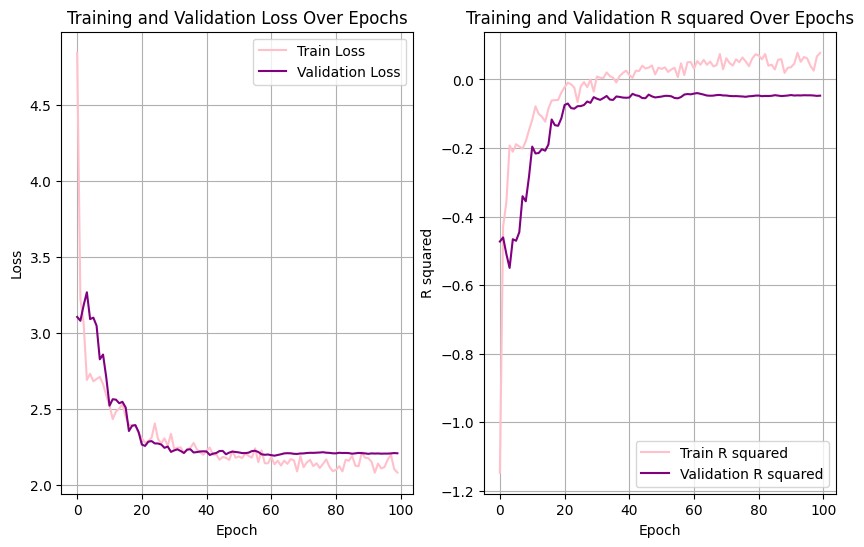

In [378]:
# tracking down the train / validation losses and r squared score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

ax1.plot(train_l, color="pink", label='Train Loss')
ax1.plot(val_l, color="purple", label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss Over Epochs')
ax1.legend()
ax1.grid()

ax2.plot(train_r, color="pink", label='Train R squared')
ax2.plot(val_r, color="purple", label='Validation R squared')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('R squared')
ax2.set_title('Training and Validation R squared Over Epochs')
ax2.legend()
ax2.grid()

plt.show()

## Results analysis

There is no more overfitting. The validation results are close to the training ones, at least in the beginning when looking at the mean squared errors. The final validation R squared is slightly lower than 0 while trained R squared is just over 0. The best validation loss is 2.2006 at epoch 60. The results do not improve after roughly 40 epochs (as we can see on both curves above) while the training ones keep slightly improving, meaning that the model started overfitting and did not learn any more useful patterns from additional epochs. 

This suggests that the training should be stopped earlier, which motivates what was done in the next iteration. 

# Iteration 4 : Implementing early stopping

## Motivation and hypothesis

As the model does not need to train after 40 epochs, early stopping was added to the training function to stop the training before overfitting starts. The default number of iterations with no change used is 10.

## Architecture and training procedure

The model architecture was not changed, but early stopping was added to the training function. As for last iteration, hyperparameters were manually tuned to get the optimal results.



In [379]:
# Defining a function that trains the model
def train_model_reg_early_stopping(model, X_train_tensor, y_train_tensor, X_test_tensor, y_test_tensor,
                                   model_save_path, num_epochs=100, batch_size=64, lr=0.01, 
                                   weight_decay=1e-4, lambda_l1=0.01, n_iter_no_change=10):

    # Loss and Optimizer
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)  # L2 regularization
    scheduler = StepLR(optimizer, step_size=10, gamma=0.5)  # Learning rate scheduler

    # Training loop
    num_batches = len(X_train_tensor) // batch_size

    train_losses = []
    val_losses = []

    train_r2 = []
    val_r2 = []

    # Initialising the early stop counter and best validation loss
    early_stop_counter = 0
    best_val_loss = np.inf

    for epoch in range(num_epochs):
        # Training phase
        model.train()
        epoch_loss = 0
        train_r2_metric = R2Score()

        for i in range(num_batches):
            start_idx = i * batch_size
            end_idx = start_idx + batch_size
            X_batch = X_train_tensor[start_idx:end_idx]
            y_batch = y_train_tensor[start_idx:end_idx]

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            # computing l1 loss and adding it to the loss function
            l1_loss = sum(torch.sum(torch.abs(param)) for param in model.parameters())
            total_loss = loss + lambda_l1*l1_loss

            total_loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            train_r2_metric.update(predictions, y_batch)
        
        train_loss = epoch_loss / num_batches
        train_losses.append(train_loss)

        # Validation phase
        model.eval()
        val_r2_metric = R2Score()

        with torch.no_grad():
            val_predictions = model(X_test_tensor)
            val_loss = criterion(val_predictions, y_test_tensor)
            val_r2_metric.update(val_predictions, y_test_tensor)

        # Check for improvement
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            early_stop_counter = 0
            torch.save(model.state_dict(), model_save_path)  # Save the best model
            print(f"Epoch {epoch+1}: New best model saved with Val Loss: {val_loss.item():.4f}")
        else:
            early_stop_counter += 1

        # Early stopping
        if early_stop_counter >= n_iter_no_change:
            print("Early stopping triggered.")
            break
        
        # Adding the validation loss to the list
        val_losses.append(val_loss.item())

        # Adding r squared scores
        train_r2.append(train_r2_metric.compute().item())
        val_r2.append(val_r2_metric.compute().item())

        scheduler.step()

        # Print progress
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")
        
    # Returning losses and r squared
    return train_losses, val_losses, train_r2, val_r2

In [380]:
input_dim = X_selected.shape[1]
model_l1reg = GeneNN_1(input_dim, init_method="he", dropout_rate=0.35)
train_l, val_l, train_r, val_r = train_model_reg_early_stopping(model=model_l1reg, model_save_path="best_model.pth",
                                            X_train_tensor=X_selected, y_train_tensor=y_train_tensor,
                                            X_test_tensor=X_test_selected, y_test_tensor=y_test_tensor,
                                            n_iter_no_change=10,
                                            batch_size=100,
                                            lr=0.01,
                                            lambda_l1=0.1)

Epoch 1: New best model saved with Val Loss: 2.6531
Epoch 9: New best model saved with Val Loss: 2.6028
Epoch 10/100, Train Loss: 2.5939, Val Loss: 2.7251
Epoch 12: New best model saved with Val Loss: 2.5746
Epoch 13: New best model saved with Val Loss: 2.5491
Epoch 14: New best model saved with Val Loss: 2.5123
Epoch 15: New best model saved with Val Loss: 2.4553
Epoch 16: New best model saved with Val Loss: 2.3505
Epoch 17: New best model saved with Val Loss: 2.3289
Epoch 18: New best model saved with Val Loss: 2.3099
Epoch 19: New best model saved with Val Loss: 2.2505
Epoch 20/100, Train Loss: 2.3747, Val Loss: 2.3730
Epoch 24: New best model saved with Val Loss: 2.2097
Epoch 25: New best model saved with Val Loss: 2.1972
Epoch 26: New best model saved with Val Loss: 2.1603
Epoch 30/100, Train Loss: 2.2619, Val Loss: 2.1850
Epoch 33: New best model saved with Val Loss: 2.1567
Epoch 40/100, Train Loss: 2.2240, Val Loss: 2.1872
Early stopping triggered.


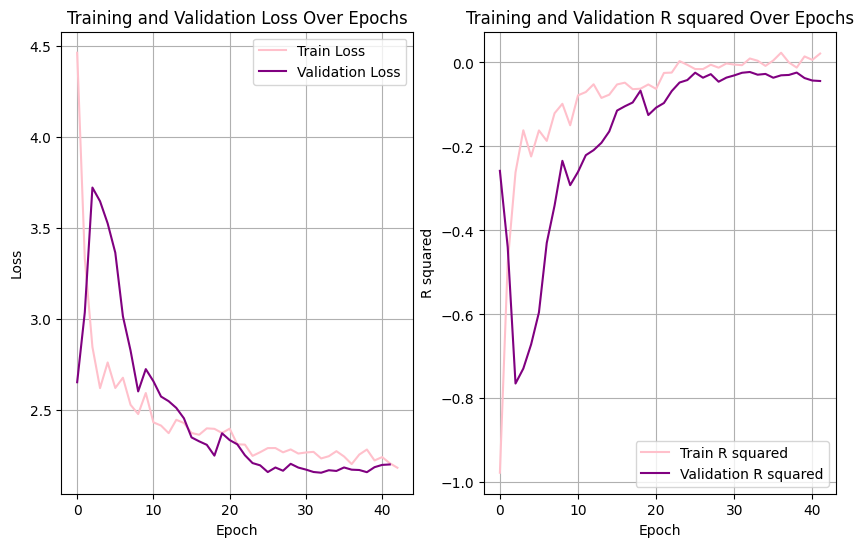

In [381]:
# tracking down the train / validation losses and r squared score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

ax1.plot(train_l, color="pink", label='Train Loss')
ax1.plot(val_l, color="purple", label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss Over Epochs')
ax1.legend()
ax1.grid()

ax2.plot(train_r, color="pink", label='Train R squared')
ax2.plot(val_r, color="purple", label='Validation R squared')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('R squared')
ax2.set_title('Training and Validation R squared Over Epochs')
ax2.legend()
ax2.grid()

plt.show()

## Results analysis

The model does not overfit anymore and does not run for more epochs than necessary. The results are similar to the ones in the last iteration. The best validation loss was 2.1567 at epoch 33, and training stopped just after epoch 40 once no improvement was seen for 10 consecutive epochs. However, the results are still not great: the R squared, either the training one or the validation one, is very close to 0, meaning that the model does not explain much of the variation in lacZ. The model converges quickly but the ceiling on validation performance suggests the architecture may be too small to capture the underlying relationships in the data. 

The next iteration changed the architecture of the network, making it wider and deeper. 

# Iteration 5 : Wider and deeper architecture

## Motivation and hypothesis

As the relationships between input features and target are not linear and highly complex, increasing the depth and width of the network might increase the results, as it might help the model learn more complex relationships.

## Architecture and training procedure

The model now has three hidden layers, the first with 500 neurons, the second with 256 neurons and the last one with 128 neurons. Again, the hyperparameters were tuned to obtain results as good as possible. Here are the final hyperparameters of our model : 



In [382]:
class GeneNN_2(nn.Module):
    def __init__(self, input_dim, init_method="xavier", dropout_rate=0.3):
        super(GeneNN_2, self).__init__()

        # Layers with Batch Normalization
        self.fc1 = nn.Linear(input_dim, 500)
        self.bn1 = nn.BatchNorm1d(500)
        self.fc2 = nn.Linear(500, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.fc4 = nn.Linear(128, 1)

        # Dropout
        self.dropout = nn.Dropout(dropout_rate)

        # Initialize weights
        self.init_weights(init_method)

    def init_weights(self, method):
        for layer in [self.fc1, self.fc2, self.fc3]:
            if method == "xavier":
                nn.init.xavier_uniform_(layer.weight)
            elif method == "he":
                nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
            elif method == "normal":
                nn.init.normal_(layer.weight, mean=0, std=0.1)
            layer.bias.data.fill_(0.01)

    def forward(self, x):
        x = F.relu(self.bn1(self.fc1(x)))
        x = self.dropout(x)
        x = F.relu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        x = F.relu(self.bn3(self.fc3(x)))
        x = self.dropout(x)
        return self.fc4(x)

In [383]:
input_dim = X_selected.shape[1]
model_5 = GeneNN_2(input_dim, init_method="he", dropout_rate=0.3)
train_l, val_l, train_r, val_r = train_model_reg_early_stopping(model=model_5, model_save_path="best_model.pth",
                                            X_train_tensor=X_selected, y_train_tensor=y_train_tensor,
                                            X_test_tensor=X_test_selected, y_test_tensor=y_test_tensor,
                                            n_iter_no_change=10,
                                            batch_size=100,
                                            lr=0.01,
                                            lambda_l1=0.05)

Epoch 1: New best model saved with Val Loss: 3.1986
Epoch 6: New best model saved with Val Loss: 3.1534
Epoch 7: New best model saved with Val Loss: 3.1175
Epoch 8: New best model saved with Val Loss: 2.8939
Epoch 9: New best model saved with Val Loss: 2.7464
Epoch 10: New best model saved with Val Loss: 2.6863
Epoch 10/100, Train Loss: 2.7886, Val Loss: 2.6863
Epoch 11: New best model saved with Val Loss: 2.6418
Epoch 13: New best model saved with Val Loss: 2.5504
Epoch 16: New best model saved with Val Loss: 2.5280
Epoch 17: New best model saved with Val Loss: 2.4099
Epoch 19: New best model saved with Val Loss: 2.2238
Epoch 20: New best model saved with Val Loss: 2.1891
Epoch 20/100, Train Loss: 2.3421, Val Loss: 2.1891
Epoch 23: New best model saved with Val Loss: 2.1874
Epoch 24: New best model saved with Val Loss: 2.1719
Epoch 26: New best model saved with Val Loss: 2.1502
Epoch 27: New best model saved with Val Loss: 2.1452
Epoch 28: New best model saved with Val Loss: 2.1304
Ep

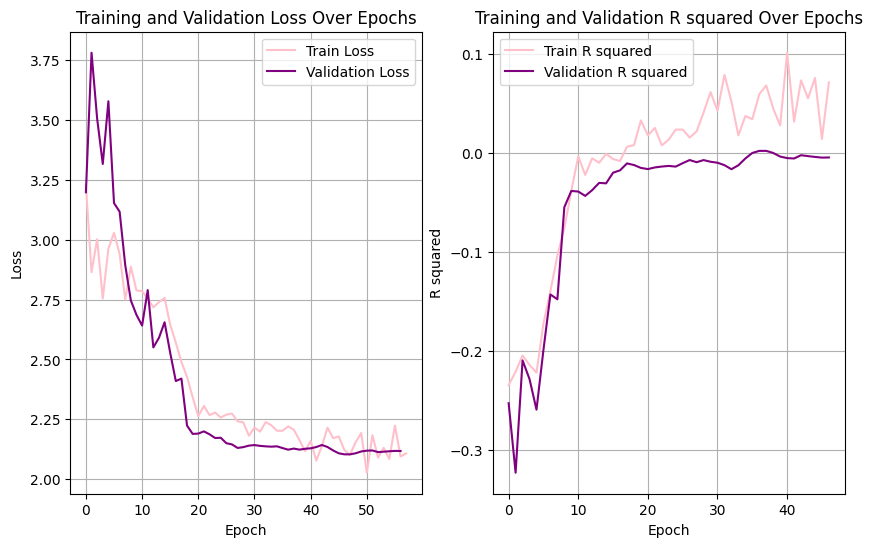

In [384]:
# tracking down the train / validation losses and r squared score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))

ax1.plot(train_l, color="pink", label='Train Loss')
ax1.plot(val_l, color="purple", label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss Over Epochs')
ax1.legend()
ax1.grid()

ax2.plot(train_r[10:], color="pink", label='Train R squared')
ax2.plot(val_r[10:], color="purple", label='Validation R squared')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('R squared')
ax2.set_title('Training and Validation R squared Over Epochs')
ax2.legend()
ax2.grid()

plt.show()

## Results analysis

The best validation loss was 2.1036 at epoch 48, an improvement from iteration 4. However, the train and validation losses remain close together throughout training, indicating that the model fits correctly to the data (it neither overfits nor underfits) and the R squared stays near zero, indicating that simply increasing capacity does not resolve the core challenge. The variation in our target variable is not actually explained by the model.

The wider architecture requires a higher L1 penalty and lower dropout to balance regularisation, suggesting there is a trade-off between model size and trainability on this dataset size. 

# Comparison between iterations

This is a comparison of the results across all iterations : 

 - Iteration 1, baseline model : train MSE = 1.7760, validation MSE = 2.3476
 - Iteration 2, feature selection : train MSE = 1.8269, validation MSE = 2.2699
 - Iteration 3, regularisation : train MSE = 2.0818, validation MSE = 2.2087
 - Iteration 4, early stopping : validation MSE = 2.1567
 - Iteration 5, wider network : train MSE = , validation MSE = 2.1036

The validation mean square erros increased steadily across all iterations, while the training ones increased. Feature selection dropped the validation mean square error the most out of everything that was tested. Increasing the model depth and width in iteration 5 provided a slight model gain, but the improvment was small compared to what was expected, suggesting that the model capacity is not the primary bottleneck.

Across all five iterations, the validation R squared remained very close to 0. This consistent pattern indicates that the models are not explaining meaningful variance in lacZ expression regardless of architecture, regularisation choice or feature selection method. 


# Limitations and potential improvements

## Limitations

The first limitation is the small size of the dataset. The dataset has a relatively small number of rows compared to datasets that are usually used to train neural networks. With only 800 training samples, the models are at a high risk of overfitting, and the near zero R^2 across all iterations suggests there may not be sufficient data for a neural network to reliably learn the underlying patterns in laccZ expression. 

Moreover, the preprocessing that was applied before and limits interpretability, which was already quite low, as the outputs of neural networks are hard to interpret. As aforementioned, it is hard to tell which variables originally had a low standard deviation, as the data has already been normalised and hence results are hard to interpret. 

The validation R squared remained near zero across all five iterations, suggesting either that the selected features do not contain sufficient information to predict lacZ, or that the dataset is too small for neural network regression to generalise effectively. 

## Improvements

Collecting more data or augmenting the existing dataset would aid in improving model performance as the dataset size appears to be the primary bottleneck. 

Alternative feature selection approaches, such as a biological understanding of which genes impact lacZ, might increase the results. 
Systematic hyperparameter tuning such as grid search could potentially identify configurations that were not explored in the five iterations.  